In [1]:
%pip install numpy pandas matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import numpy as np
import pandas as pd

np.random.seed(42)

n = 2000

# Housing features
living_area = np.random.uniform(800, 4000, n)

df = pd.DataFrame({
    "property_id": np.arange(1, n + 1),

    "living_area_sqft": living_area,

    "total_interior_sqft":
        living_area + np.random.normal(0, 100, n),

    "footprint_sqft":
        living_area * 0.75 + np.random.normal(0, 80, n),

    "garage_capacity_cars":
        np.random.randint(0, 4, n),

    "lot_size_sqft":
        np.random.uniform(1500, 10000, n),

    "room_count_above_ground":
        np.random.randint(2, 9, n)
})

# Generate housing sale prices
df["sale_price"] = (
    50000
    + 150 * df["living_area_sqft"]
    + 10 * df["lot_size_sqft"]
    + 15000 * df["garage_capacity_cars"]
    + 8000 * df["room_count_above_ground"]
    + np.random.normal(0, 25000, n)
)

df.head()

,property_id,living_area_sqft,total_interior_sqft,footprint_sqft,garage_capacity_cars,lot_size_sqft,room_count_above_ground,sale_price
0,1,1998.528380,1910.730122,1526.633083,1,5333.385273,4,423077.775253
1,2,3842.285781,3759.597745,3082.638860,2,2356.399174,4,720303.040431
2,3,3142.380614,3119.732725,2209.579241,0,7513.943961,7,665406.448377
3,4,2715.707149,2752.443700,2034.197913,2,1764.986727,6,521879.659101
4,5,1299.259649,1390.618112,1025.688172,3,8896.671869,4,401285.229080


In [4]:
print("Dataset Shape:", df.shape)

print("\nTotal Rows:", len(df))

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (2000, 8)

Total Rows: 2000

Column Names:
['property_id', 'living_area_sqft', 'total_interior_sqft', 'footprint_sqft', 'garage_capacity_cars', 'lot_size_sqft', 'room_count_above_ground', 'sale_price']


In [5]:
df.to_csv(
    "multicollinear_housing_features.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [6]:
print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (2000, 8)

Data Types:
property_id                  int64
living_area_sqft           float64
total_interior_sqft        float64
footprint_sqft             float64
garage_capacity_cars         int32
lot_size_sqft              float64
room_count_above_ground      int32
sale_price                 float64
dtype: object

Missing Values:
property_id                0
living_area_sqft           0
total_interior_sqft        0
footprint_sqft             0
garage_capacity_cars       0
lot_size_sqft              0
room_count_above_ground    0
sale_price                 0
dtype: int64

Duplicate Rows: 0


In [7]:
df.describe().round(2)

,property_id,living_area_sqft,total_interior_sqft,footprint_sqft,garage_capacity_cars,lot_size_sqft,room_count_above_ground,sale_price
count,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00
mean,1000.50,2395.64,2396.40,1793.72,1.46,5671.50,5.04,527688.06
std,577.49,935.07,942.46,703.25,1.13,2408.43,2.01,145468.70
min,1.00,810.30,623.45,474.21,0.00,1500.45,2.00,219107.74
25%,500.75,1561.75,1572.44,1181.31,0.00,3643.85,3.00,404438.40
50%,1000.50,2423.52,2433.13,1802.03,1.00,5634.25,5.00,532523.55
75%,1500.25,3202.17,3195.94,2395.37,2.00,7704.18,7.00,647575.13
max,2000.00,3999.10,4152.67,3097.87,3.00,9995.79,8.00,858333.33


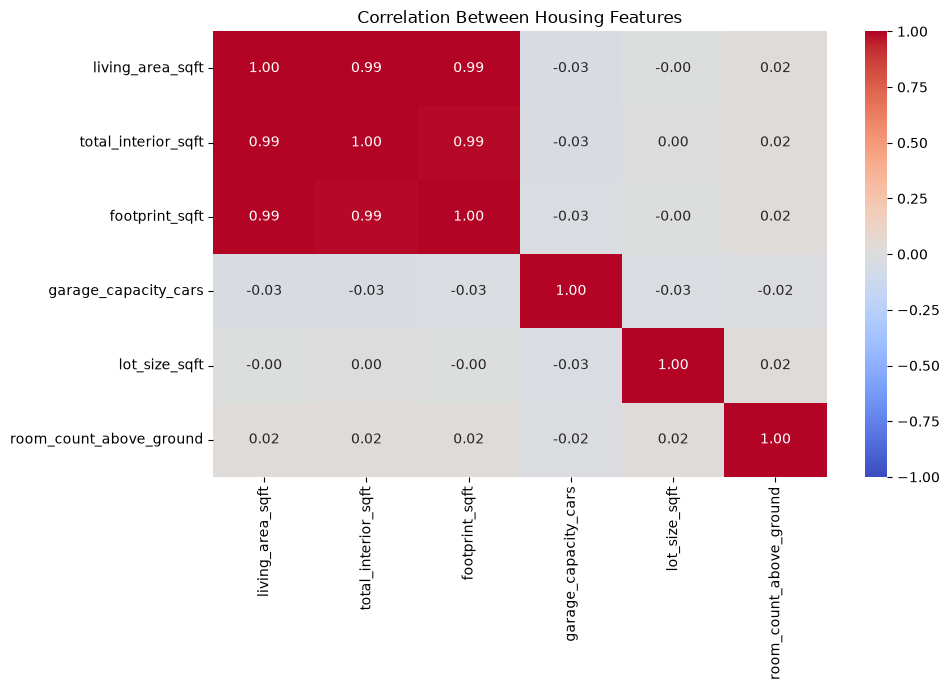

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

features = [
    "living_area_sqft",
    "total_interior_sqft",
    "footprint_sqft",
    "garage_capacity_cars",
    "lot_size_sqft",
    "room_count_above_ground"
]

corr = df[features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Housing Features")
plt.tight_layout()
plt.show()

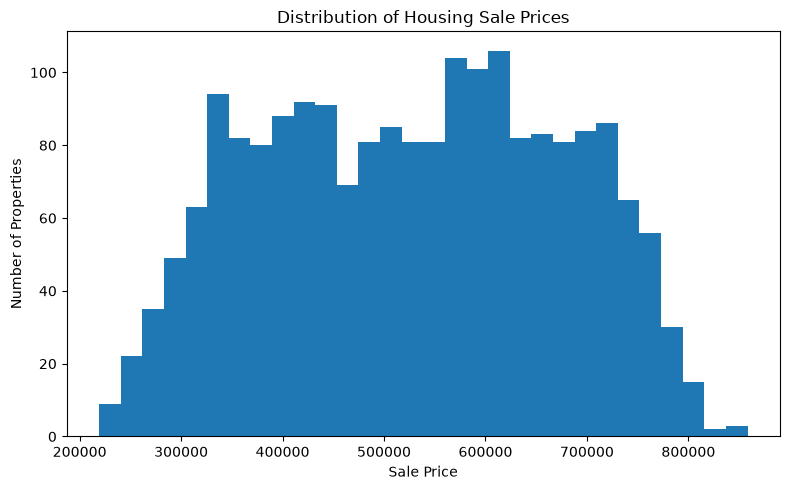

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(df["sale_price"], bins=30)

plt.title("Distribution of Housing Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Number of Properties")

plt.tight_layout()
plt.show()

In [10]:
X = df[features].to_numpy(dtype=float)

y = df["sale_price"].to_numpy(dtype=float)

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

Input Shape: (2000, 6)
Target Shape: (2000,)


In [11]:
# Shuffle dataset
rng = np.random.default_rng(42)

indices = rng.permutation(len(X))

split = int(0.8 * len(X))

train_idx = indices[:split]
test_idx = indices[split:]

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

# Standardization using training data only
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

# Center target using training mean
y_mean = y_train.mean()

y_train_centered = y_train - y_mean

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1600
Testing samples: 400


In [12]:
# Linear Regression using NumPy

def linear_regression(X, y):
    n = X.shape[0]

    # Add intercept column
    X_bias = np.column_stack([
        np.ones(n),
        X
    ])

    # Calculate coefficients
    beta = np.linalg.pinv(X_bias) @ y

    return beta

# Train model
beta = linear_regression(
    X_train_scaled,
    y_train_centered
)

print("Intercept:", beta[0])
print("Coefficients:", beta[1:])

Intercept: -2.751221472863108e-11
Coefficients: [141750.1738082    2563.9158163   -3905.10456414  16496.67750631
  23359.95069325  17238.02678873]


In [13]:
# Predict test data

X_test_bias = np.column_stack([
    np.ones(len(X_test_scaled)),
    X_test_scaled
])

y_pred = X_test_bias @ beta + y_mean

# Calculate R2 score
ss_res = np.sum((y_test - y_pred) ** 2)
ss_tot = np.sum((y_test - y_test.mean()) ** 2)

r2 = 1 - (ss_res / ss_tot)

# Calculate RMSE
rmse = np.sqrt(np.mean((y_test - y_pred) ** 2))

print("Linear Regression R2:", round(r2, 4))
print("Linear Regression RMSE:", round(rmse, 2))

Linear Regression R2: 0.9716
Linear Regression RMSE: 23707.15


In [14]:
def ridge_regression(X, y, alpha):

    n = X.shape[0]

    X_bias = np.column_stack([
        np.ones(n),
        X
    ])

    # L2 regularization
    I = np.eye(X_bias.shape[1])

    # Do not penalize intercept
    I[0, 0] = 0

    beta = np.linalg.solve(
        X_bias.T @ X_bias + alpha * I,
        X_bias.T @ y
    )

    return beta

In [15]:
ridge_beta = ridge_regression(
    X_train_scaled,
    y_train_centered,
    alpha=10
)

print("Ridge Coefficients:")
print(ridge_beta[1:])

Ridge Coefficients:
[83891.56556986 31406.48159704 24935.62825288 16339.65888284
 23215.94519483 16885.34893389]


In [16]:
def lasso_regression(X, y, alpha, iterations=5000):

    n, p = X.shape

    beta = np.zeros(p)

    for _ in range(iterations):

        for j in range(p):

            residual = y - X @ beta + X[:, j] * beta[j]

            rho = np.dot(X[:, j], residual) / n

            # Soft thresholding
            if rho > alpha:
                beta[j] = rho - alpha

            elif rho < -alpha:
                beta[j] = rho + alpha

            else:
                beta[j] = 0

    return beta

In [17]:
lasso_beta = lasso_regression(
    X_train_scaled,
    y_train_centered,
    alpha=1000
)

print("Lasso Coefficients:")
print(lasso_beta)

Lasso Coefficients:
[137191.13305462   2236.45313769      0.          15433.16640672
  22378.53015206  16227.64950142]


In [18]:
alphas = np.logspace(-2, 5, 100)

ridge_paths = []
lasso_paths = []

for alpha in alphas:

    # Ridge coefficients
    ridge_beta = ridge_regression(
        X_train_scaled,
        y_train_centered,
        alpha
    )

    ridge_paths.append(ridge_beta[1:])

    # Lasso coefficients
    lasso_beta = lasso_regression(
        X_train_scaled,
        y_train_centered,
        alpha,
        iterations=5000
    )

    lasso_paths.append(lasso_beta)

ridge_paths = np.array(ridge_paths)
lasso_paths = np.array(lasso_paths)

print("Coefficient paths generated successfully!")

Coefficient paths generated successfully!


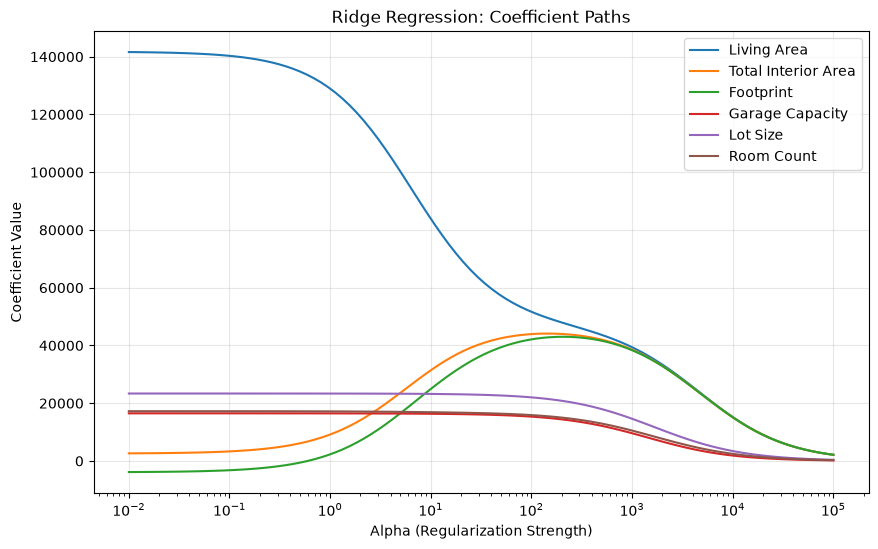

In [19]:
# Feature names
feature_names = [
    "Living Area",
    "Total Interior Area",
    "Footprint",
    "Garage Capacity",
    "Lot Size",
    "Room Count"
]

# Ridge coefficient path
plt.figure(figsize=(10, 6))

for i in range(len(feature_names)):
    plt.plot(
        alphas,
        ridge_paths[:, i],
        label=feature_names[i]
    )

plt.xscale("log")
plt.xlabel("Alpha (Regularization Strength)")
plt.ylabel("Coefficient Value")
plt.title("Ridge Regression: Coefficient Paths")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

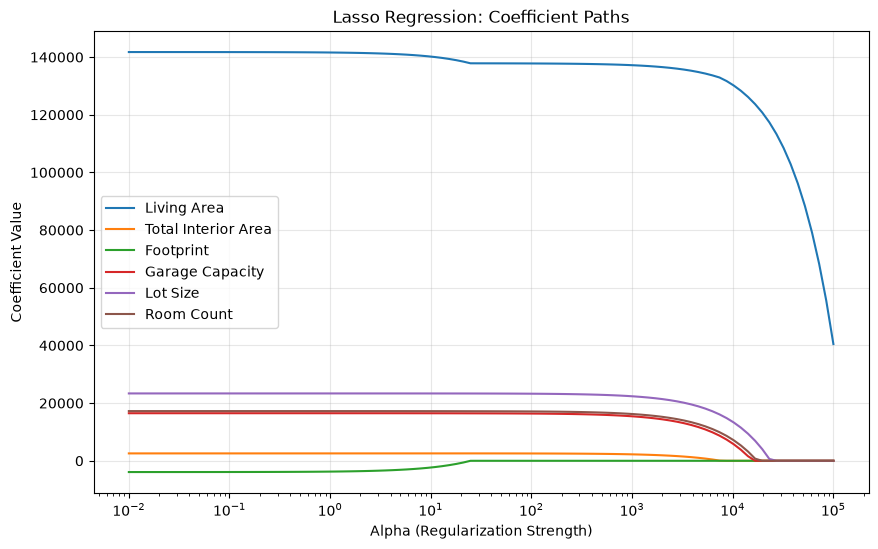

In [20]:
plt.figure(figsize=(10, 6))

for i in range(len(feature_names)):
    plt.plot(
        alphas,
        lasso_paths[:, i],
        label=feature_names[i]
    )

plt.xscale("log")
plt.xlabel("Alpha (Regularization Strength)")
plt.ylabel("Coefficient Value")
plt.title("Lasso Regression: Coefficient Paths")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

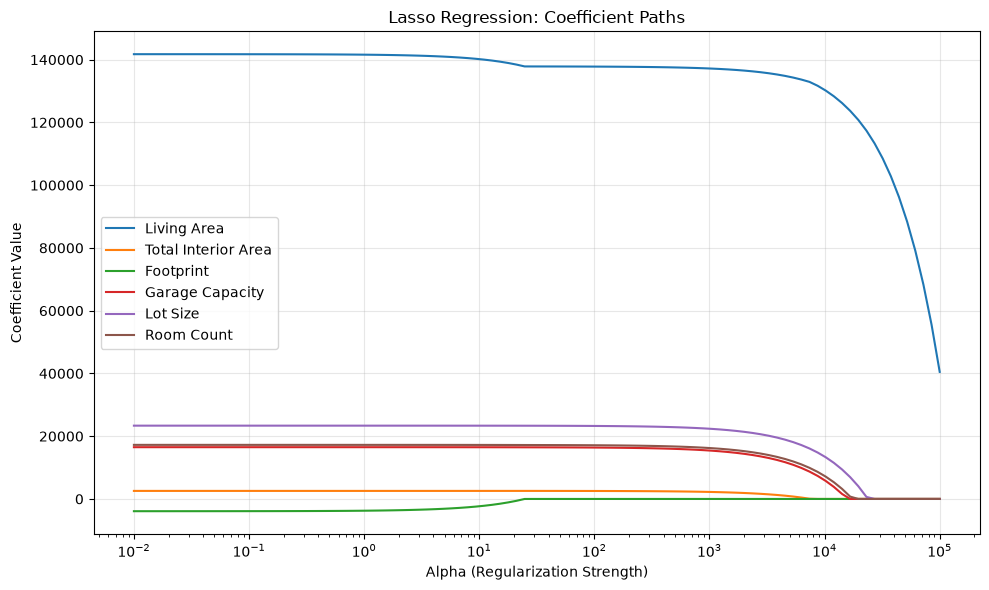

In [21]:
plt.figure(figsize=(10, 6))

for i in range(len(feature_names)):
    plt.plot(
        alphas,
        lasso_paths[:, i],
        label=feature_names[i]
    )

plt.xscale("log")
plt.xlabel("Alpha (Regularization Strength)")
plt.ylabel("Coefficient Value")
plt.title("Lasso Regression: Coefficient Paths")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

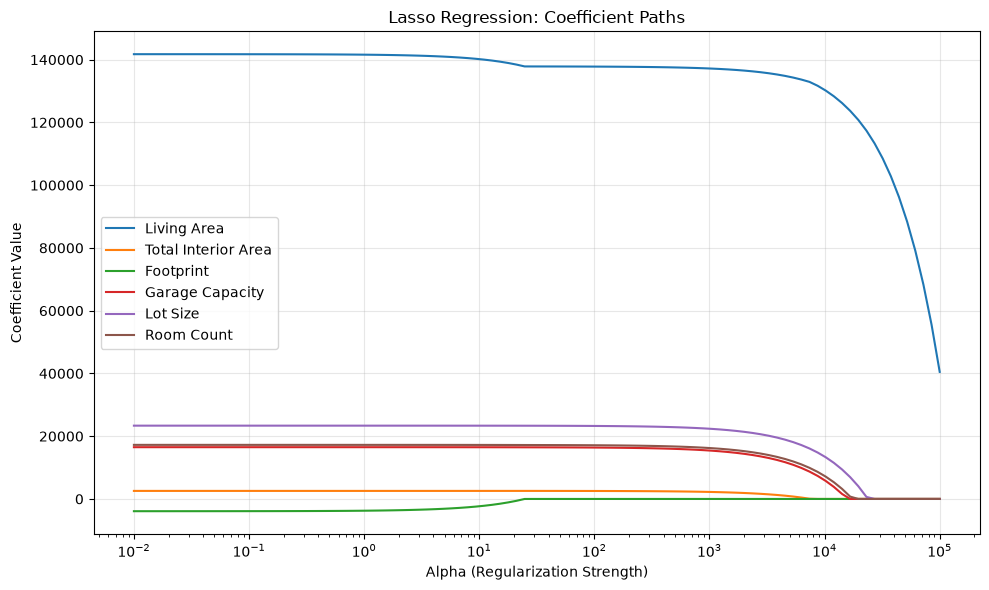

In [22]:
plt.figure(figsize=(10, 6))

for i in range(len(feature_names)):
    plt.plot(
        alphas,
        lasso_paths[:, i],
        label=feature_names[i]
    )

plt.xscale("log")
plt.xlabel("Alpha (Regularization Strength)")
plt.ylabel("Coefficient Value")
plt.title("Lasso Regression: Coefficient Paths")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
def calculate_vif(X):

    n, p = X.shape

    vif_values = []

    for j in range(p):

        # Target feature
        y_feature = X[:, j]

        # Remaining features
        X_other = np.delete(X, j, axis=1)

        # Add intercept
        X_bias = np.column_stack([
            np.ones(n),
            X_other
        ])

        # Regression coefficients
        beta = np.linalg.lstsq(
            X_bias,
            y_feature,
            rcond=None
        )[0]

        # Predicted feature values
        y_pred = X_bias @ beta

        # Calculate R-squared
        ss_res = np.sum((y_feature - y_pred) ** 2)
        ss_tot = np.sum((y_feature - y_feature.mean()) ** 2)

        r2 = 1 - ss_res / ss_tot

        # Calculate VIF
        vif = 1 / (1 - r2)

        vif_values.append(vif)

    return vif_values

In [24]:
vif_before = calculate_vif(X_train_scaled)

vif_table = pd.DataFrame({
    "Feature": features,
    "VIF": vif_before
})

vif_table

,Feature,VIF
0,living_area_sqft,166.459114
1,total_interior_sqft,88.433506
2,footprint_sqft,78.612729
3,garage_capacity_cars,1.002170
4,lot_size_sqft,1.000894
5,room_count_above_ground,1.003777


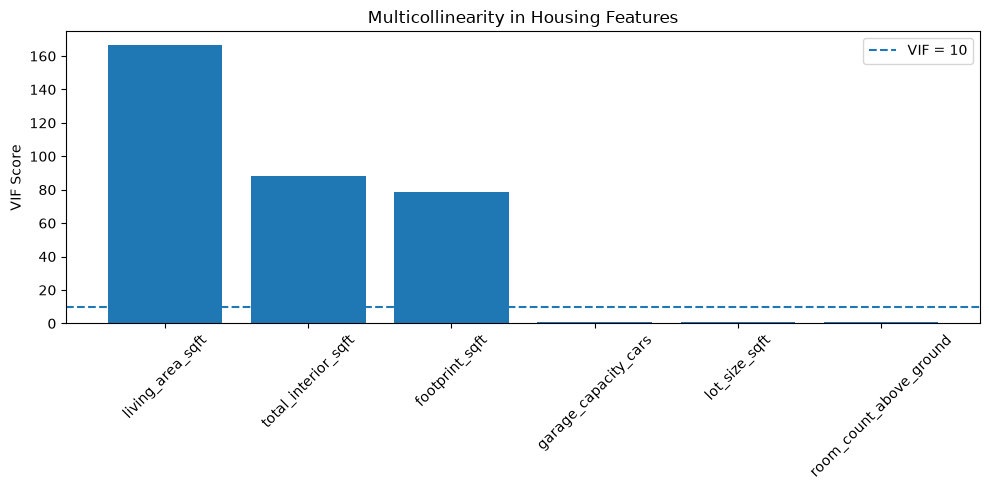

In [25]:
plt.figure(figsize=(10, 5))

plt.bar(
    features,
    vif_before
)

plt.axhline(
    y=10,
    linestyle="--",
    label="VIF = 10"
)

plt.xticks(rotation=45)

plt.ylabel("VIF Score")
plt.title("Multicollinearity in Housing Features")

plt.legend()
plt.tight_layout()
plt.show()

In [26]:
# Compare all three regression models

linear_scores = cross_validate(
    X, y, model="linear"
)

ridge_scores = cross_validate(
    X, y, model="ridge", alpha=10
)

lasso_scores = cross_validate(
    X, y, model="lasso", alpha=1000
)

# Final comparison table

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],

    "Mean R2": [
        linear_scores["R2"].mean(),
        ridge_scores["R2"].mean(),
        lasso_scores["R2"].mean()
    ],

    "Mean RMSE": [
        linear_scores["RMSE"].mean(),
        ridge_scores["RMSE"].mean(),
        lasso_scores["RMSE"].mean()
    ]
})

results.round(4)

NameError: name 'cross_validate' is not defined

In [27]:
def cross_validate(X, y, model, alpha=0, folds=5):

    indices = np.random.default_rng(42).permutation(len(X))
    fold_indices = np.array_split(indices, folds)

    scores = []

    for i in range(folds):

        test_idx = fold_indices[i]

        train_idx = np.concatenate([
            fold_indices[j]
            for j in range(folds) if j != i
        ])

        X_train = X[train_idx]
        X_test = X[test_idx]

        y_train = y[train_idx]
        y_test = y[test_idx]

        # Feature scaling
        mean = X_train.mean(axis=0)
        std = X_train.std(axis=0)

        X_train = (X_train - mean) / std
        X_test = (X_test - mean) / std

        y_mean = y_train.mean()
        y_train = y_train - y_mean

        # Train model
        if model == "linear":
            beta = linear_regression(X_train, y_train)

        elif model == "ridge":
            beta = ridge_regression(X_train, y_train, alpha)

        elif model == "lasso":
            beta = lasso_regression(
                X_train, y_train, alpha, iterations=5000
            )

        # Predict
        X_test_bias = np.column_stack([
            np.ones(len(X_test)),
            X_test
        ])

        y_pred = X_test_bias @ beta + y_mean

        # R2
        ss_res = np.sum((y_test - y_pred) ** 2)
        ss_tot = np.sum((y_test - y_test.mean()) ** 2)

        r2 = 1 - ss_res / ss_tot

        # RMSE
        rmse = np.sqrt(np.mean((y_test - y_pred) ** 2))

        scores.append({
            "R2": r2,
            "RMSE": rmse
        })

    return pd.DataFrame(scores)

In [28]:
linear_scores = cross_validate(X, y, model="linear")

ridge_scores = cross_validate(
    X, y, model="ridge", alpha=10
)

lasso_scores = cross_validate(
    X, y, model="lasso", alpha=1000
)

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],
    "Mean R2": [
        linear_scores["R2"].mean(),
        ridge_scores["R2"].mean(),
        lasso_scores["R2"].mean()
    ],
    "Mean RMSE": [
        linear_scores["RMSE"].mean(),
        ridge_scores["RMSE"].mean(),
        lasso_scores["RMSE"].mean()
    ]
})

results.round(4)

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 6 is different from 7)

In [29]:
def lasso_regression(X, y, alpha, iterations=5000):

    n, p = X.shape

    beta = np.zeros(p)

    for _ in range(iterations):

        for j in range(p):

            residual = y - X @ beta + X[:, j] * beta[j]

            rho = np.dot(X[:, j], residual) / n

            if rho > alpha:
                beta[j] = rho - alpha

            elif rho < -alpha:
                beta[j] = rho + alpha

            else:
                beta[j] = 0

    # Add intercept as first coefficient
    return np.concatenate([[0], beta])

In [30]:
linear_scores = cross_validate(
    X, y, model="linear"
)

ridge_scores = cross_validate(
    X, y, model="ridge", alpha=10
)

lasso_scores = cross_validate(
    X, y, model="lasso", alpha=1000
)

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],

    "Mean R2": [
        linear_scores["R2"].mean(),
        ridge_scores["R2"].mean(),
        lasso_scores["R2"].mean()
    ],

    "Mean RMSE": [
        linear_scores["RMSE"].mean(),
        ridge_scores["RMSE"].mean(),
        lasso_scores["RMSE"].mean()
    ]
})

results.round(4)

,Model,Mean R2,Mean RMSE
0,Linear Regression,0.9721,24215.2171
1,Ridge Regression,0.9713,24582.9969
2,Lasso Regression,0.9719,24294.4109


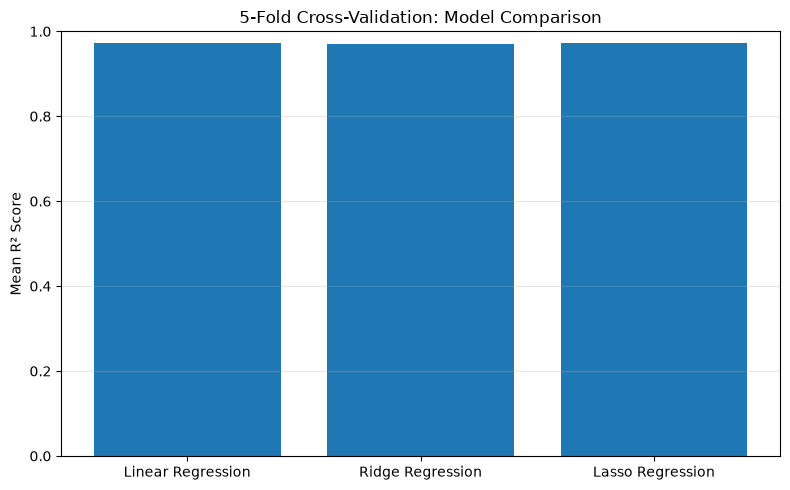

In [31]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Model"],
    results["Mean R2"]
)

plt.ylabel("Mean R² Score")
plt.title("5-Fold Cross-Validation: Model Comparison")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [32]:
print("Cross-Validation Results")
display(results.round(4))

Cross-Validation Results


,Model,Mean R2,Mean RMSE
0,Linear Regression,0.9721,24215.2171
1,Ridge Regression,0.9713,24582.9969
2,Lasso Regression,0.9719,24294.4109


In [33]:
coefficient_comparison = pd.DataFrame({
    "Feature": features,
    "Linear": linear_beta[1:],
    "Ridge": ridge_beta[1:],
    "Lasso": lasso_beta[1:]
})

display(coefficient_comparison.round(4))

NameError: name 'linear_beta' is not defined

In [34]:
print("Linear:", linear_beta if 'linear_beta' in globals() else "Not found")
print("Ridge:", ridge_beta if 'ridge_beta' in globals() else "Not found")
print("Lasso:", lasso_beta if 'lasso_beta' in globals() else "Not found")

Linear: Not found
Ridge: [-3.54779314e-11  2.14565603e+03  2.13423389e+03  2.13282479e+03
  1.97475791e+02  4.02969037e+02  2.87264114e+02]
Lasso: [40493.8889303     0.            0.            0.            0.
     0.       ]


In [35]:
# Coefficient comparison

linear_model = LinearRegression()
ridge_model = Ridge(alpha=10)
lasso_model = Lasso(alpha=1000)

linear_model.fit(X_train_scaled, y_train)
ridge_model.fit(X_train_scaled, y_train)
lasso_model.fit(X_train_scaled, y_train)

coefficient_comparison = pd.DataFrame({
    "Feature": features,
    "Linear": linear_model.coef_,
    "Ridge": ridge_model.coef_,
    "Lasso": lasso_model.coef_
})

display(coefficient_comparison.round(4))

NameError: name 'LinearRegression' is not defined

In [36]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

In [37]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

linear_model = LinearRegression()
ridge_model = Ridge(alpha=10)
lasso_model = Lasso(alpha=1000)

linear_model.fit(X_train_scaled, y_train)
ridge_model.fit(X_train_scaled, y_train)
lasso_model.fit(X_train_scaled, y_train)

coefficient_comparison = pd.DataFrame({
    "Feature": features,
    "Linear": linear_model.coef_,
    "Ridge": ridge_model.coef_,
    "Lasso": lasso_model.coef_
})

display(coefficient_comparison.round(4))

,Feature,Linear,Ridge,Lasso
0,living_area_sqft,141750.1738,83891.5656,138399.6158
1,total_interior_sqft,2563.9158,31406.4816,1034.7240
2,footprint_sqft,-3905.1046,24935.6283,0.0000
3,garage_capacity_cars,16496.6775,16339.6589,15431.1301
4,lot_size_sqft,23359.9507,23215.9452,22379.6394
5,room_count_above_ground,17238.0268,16885.3489,16230.9539


In [38]:
from sklearn.metrics import r2_score, mean_squared_error
import pandas as pd

models = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Lasso Regression": lasso_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)

    results.append({
        "Model": name,
        "R2 Score": r2_score(y_test, y_pred),
        "RMSE": mean_squared_error(y_test, y_pred) ** 0.5
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,R2 Score,RMSE
0,Linear Regression,0.9716,23707.1465
1,Ridge Regression,0.9713,23837.9602
2,Lasso Regression,0.9716,23713.2181


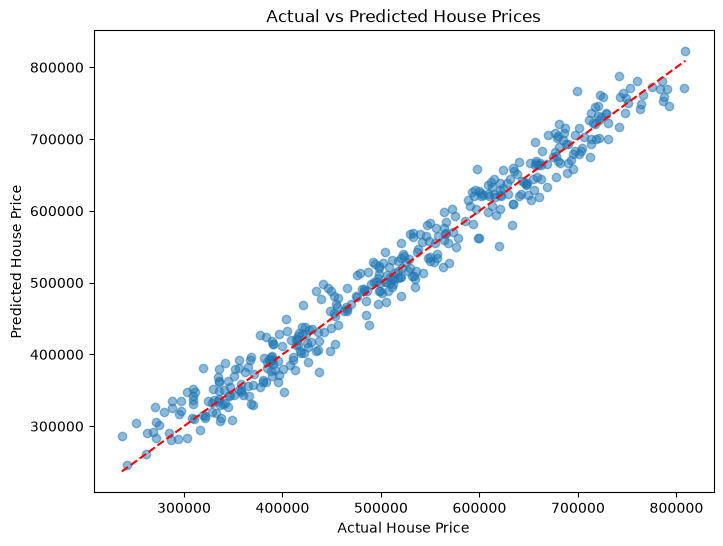

In [39]:
import matplotlib.pyplot as plt

best_model = linear_model

y_pred = best_model.predict(X_test_scaled)

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [40]:
# Final Model Performance

best_model = results_df.loc[results_df["R2 Score"].idxmax()]

print("Best Model:", best_model["Model"])
print("R2 Score:", best_model["R2 Score"])
print("RMSE:", best_model["RMSE"])

Best Model: Linear Regression
R2 Score: 0.971638157905276
RMSE: 23707.146510023606
